In [1]:
# import tools for working with file paths
from pathlib import Path

# import libraries for reading and processing raster data
import rasterio
import numpy as np

# import tools for mapping raster data
import matplotlib.pyplot as plt
from rasterio.plot import show
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

In [2]:
# set the data folder
data_dir = Path("data/tutorial07-data")

# define the paths to the land-cover rasters
raster_2001_path = data_dir / "cugir-008002/nlcd2001_ny.tif"
raster_2016_path = data_dir / "cugir-009031/nlcd2016_ny.tif"

# confirm that both raster files are available
print("2001 raster found:", raster_2001_path.is_file())
print("2016 raster found:", raster_2016_path.is_file())

2001 raster found: True
2016 raster found: True


In [3]:
# inspect each raster without loading its pixel values into memory
for year, raster_path in [
    (2001, raster_2001_path),
    (2016, raster_2016_path)
]:
    with rasterio.open(raster_path) as src:
        print(f"\nLand cover {year}")
        print("CRS:", src.crs)
        print("Pixel size:", src.res)
        print("Dimensions:", src.width, "columns ×", src.height, "rows")
        print("Bounds:", src.bounds)
        print("NoData value:", src.nodata)
        print("Data type:", src.dtypes[0])

# check whether the two rasters share exactly the same grid
with rasterio.open(raster_2001_path) as src_2001:
    with rasterio.open(raster_2016_path) as src_2016:
        same_grid = (
            src_2001.crs == src_2016.crs
            and src_2001.transform == src_2016.transform
            and src_2001.shape == src_2016.shape
        )

print("\nSame raster grid:", same_grid)


Land cover 2001
CRS: EPSG:5070
Pixel size: (30.00015662867623, 30.000307810094498)
Dimensions: 22610 columns × 16989 rows
Bounds: BoundingBox(left=1319354.1624369847, bottom=2149032.6053893133, right=1997657.7038113542, top=2658707.8347750087)
NoData value: 0.0
Data type: uint8

Land cover 2016
CRS: EPSG:5070
Pixel size: (30.0, 30.0)
Dimensions: 22610 columns × 16989 rows
Bounds: BoundingBox(left=1319355.0, bottom=2149035.0, right=1997655.0, top=2658705.0)
NoData value: 0.0
Data type: uint8

Same raster grid: False


In [4]:
# import tools for aligning raster grids
from rasterio.warp import reproject, Resampling

# create a folder for processed rasters
output_dir = Path("Tutorial07_output")
output_dir.mkdir(parents=True, exist_ok=True)

# define the output path for the aligned 2001 raster
aligned_2001_path = output_dir / "nlcd2001_aligned.tif"

# use the 2016 raster as the reference grid
with rasterio.open(raster_2016_path) as reference:
    profile = reference.profile.copy()

    # store land-cover codes as compressed unsigned integers
    profile.update(
        driver="GTiff",
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw"
    )

    # align the 2001 raster without loading the entire array into memory
    with rasterio.open(raster_2001_path) as source:
        with rasterio.open(aligned_2001_path, "w", **profile) as target:
            reproject(
                source=rasterio.band(source, 1),
                destination=rasterio.band(target, 1),
                src_transform=source.transform,
                src_crs=source.crs,
                src_nodata=source.nodata,
                dst_transform=reference.transform,
                dst_crs=reference.crs,
                dst_nodata=0,
                resampling=Resampling.nearest
            )

# confirm that the aligned raster matches the reference grid
with rasterio.open(aligned_2001_path) as aligned:
    with rasterio.open(raster_2016_path) as reference:
        print(
            "Same raster grid:",
            aligned.crs == reference.crs
            and aligned.transform == reference.transform
            and aligned.shape == reference.shape
        )

Same raster grid: True


In [5]:
# define the output paths for the agricultural rasters
agriculture_2001_path = output_dir / "agriculture_2001.tif"
agriculture_2016_path = output_dir / "agriculture_2016.tif"

# reclassify both years using the aligned input grids
for source_path, target_path in [
    (aligned_2001_path, agriculture_2001_path),
    (raster_2016_path, agriculture_2016_path)
]:
    with rasterio.open(source_path) as source:

        # preserve the grid and reserve 255 for missing data
        profile = source.profile.copy()
        profile.update(
            driver="GTiff",
            dtype="uint8",
            count=1,
            nodata=255,
            compress="lzw"
        )

        with rasterio.open(target_path, "w", **profile) as target:
            for _, window in source.block_windows(1):

                # read one block and its missing-data mask
                land_cover = source.read(1, window=window, masked=True)

                # assign 1 to agricultural classes and 0 to other classes
                agriculture = np.isin(
                    land_cover.data,
                    [81, 82]
                ).astype("uint8")

                # preserve missing data as a separate value
                agriculture[np.ma.getmaskarray(land_cover)] = 255

                # write the reclassified block
                target.write(agriculture, 1, window=window)

    print("Saved:", target_path.name)

Saved: agriculture_2001.tif
Saved: agriculture_2016.tif


In [6]:
# define the output path for the change raster
change_path = output_dir / "agriculture_change_2001_2016.tif"

# open the two reclassified rasters
with rasterio.open(agriculture_2001_path) as src_2001:
    with rasterio.open(agriculture_2016_path) as src_2016:

        # use signed integers to preserve negative change values
        # reserve -128 for pixels missing in either year
        profile = src_2016.profile.copy()
        profile.update(
            driver="GTiff",
            dtype="int8",
            count=1,
            nodata=-128,
            compress="lzw"
        )

        with rasterio.open(change_path, "w", **profile) as target:
            for _, window in src_2016.block_windows(1):

                # read the same pixel window from both years
                agriculture_2001 = src_2001.read(
                    1, window=window, masked=True
                )
                agriculture_2016 = src_2016.read(
                    1, window=window, masked=True
                )

                # identify pixels with missing data in either year
                missing = (
                    np.ma.getmaskarray(agriculture_2001)
                    | np.ma.getmaskarray(agriculture_2016)
                )

                # convert to signed integers before subtracting
                change = (
                    agriculture_2016.data.astype("int16")
                    - agriculture_2001.data.astype("int16")
                )

                # preserve missing data separately from unchanged areas
                change[missing] = -128

                # save the change values for this window
                target.write(
                    change.astype("int8"),
                    1,
                    window=window
                )

print("Saved:", change_path.name)

Saved: agriculture_change_2001_2016.tif


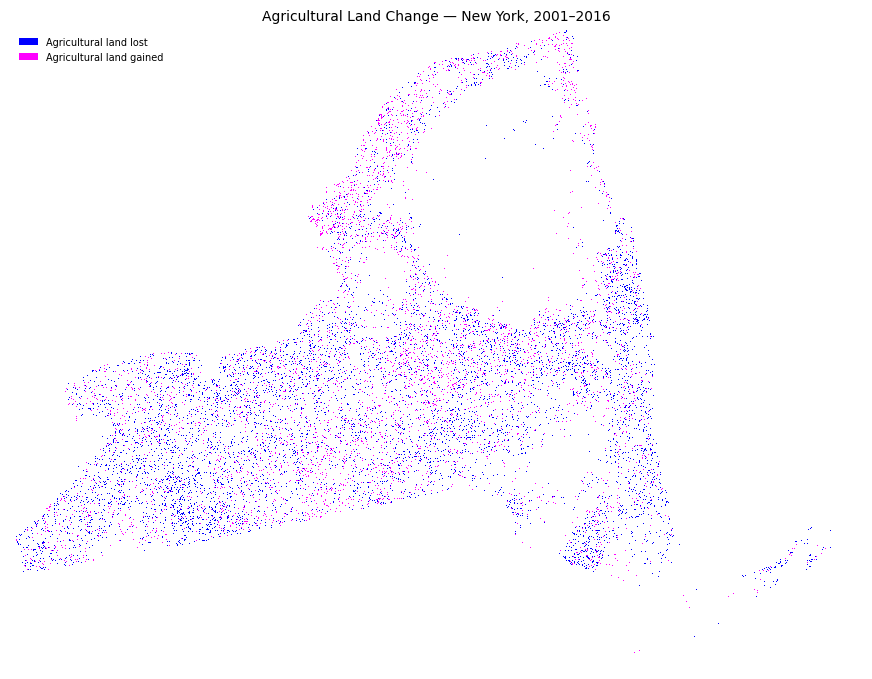

In [7]:
# import tools for raster map extents and legend entries
from rasterio.plot import plotting_extent
from matplotlib.patches import Patch

# read a reduced-resolution preview for faster plotting
# the full-resolution change raster remains unchanged
with rasterio.open(change_path) as source:
    scale = max(source.width, source.height) / 2000

    preview = source.read(
        1,
        out_shape=(
            max(1, round(source.height / scale)),
            max(1, round(source.width / scale))
        ),
        masked=True,
        resampling=Resampling.nearest
    )

    extent = plotting_extent(source)

# hide pixels with unchanged agricultural status
change_preview = np.ma.masked_where(preview == 0, preview)

# define colors for loss, unchanged status, and gain
change_cmap = ListedColormap(["#0000ff", "#ffffff", "#ff00ff"])
change_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], change_cmap.N)

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# display the change raster in its geographic position
ax.imshow(
    change_preview,
    extent=extent,
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

# create a legend for agricultural loss and gain
legend_items = [
    Patch(facecolor="#0000ff", label="Agricultural land lost"),
    Patch(facecolor="#ff00ff", label="Agricultural land gained")
]

# format the map and legend
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)
ax.set_title("Agricultural Land Change — New York, 2001–2016", fontsize=10)
ax.set_axis_off()

plt.show()

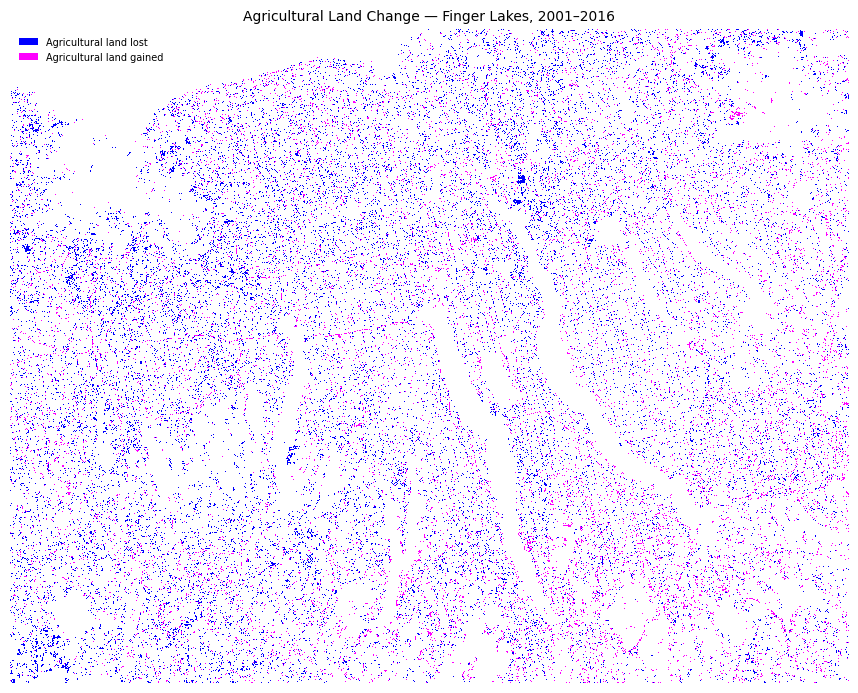

In [8]:
# import tools for converting geographic bounds into raster windows
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds, bounds

# define a study area around the Finger Lakes
# coordinates are longitude and latitude: west, south, east, north
study_bounds = (-77.8, 42.4, -76.2, 43.2)

with rasterio.open(change_path) as source:

    # convert the study area bounds to the raster coordinate system
    projected_bounds = transform_bounds(
        "EPSG:4326",
        source.crs,
        *study_bounds
    )

    # identify the pixel window covering the study area
    study_window = from_bounds(
        *projected_bounds,
        transform=source.transform
    ).round_offsets().round_lengths()

    # read the study area at full resolution
    study_change = source.read(
        1,
        window=study_window,
        masked=True
    )

    # calculate the geographic extent of the selected pixel window
    left, bottom, right, top = bounds(
        study_window,
        source.transform
    )

# hide pixels with unchanged agricultural status
study_change = np.ma.masked_where(study_change == 0, study_change)

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# display agricultural loss and gain using the existing color scheme
ax.imshow(
    study_change,
    extent=(left, right, bottom, top),
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

# format the legend and title
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)
ax.set_title(
    "Agricultural Land Change — Finger Lakes, 2001–2016",
    fontsize=10
)
ax.set_axis_off()

plt.show()

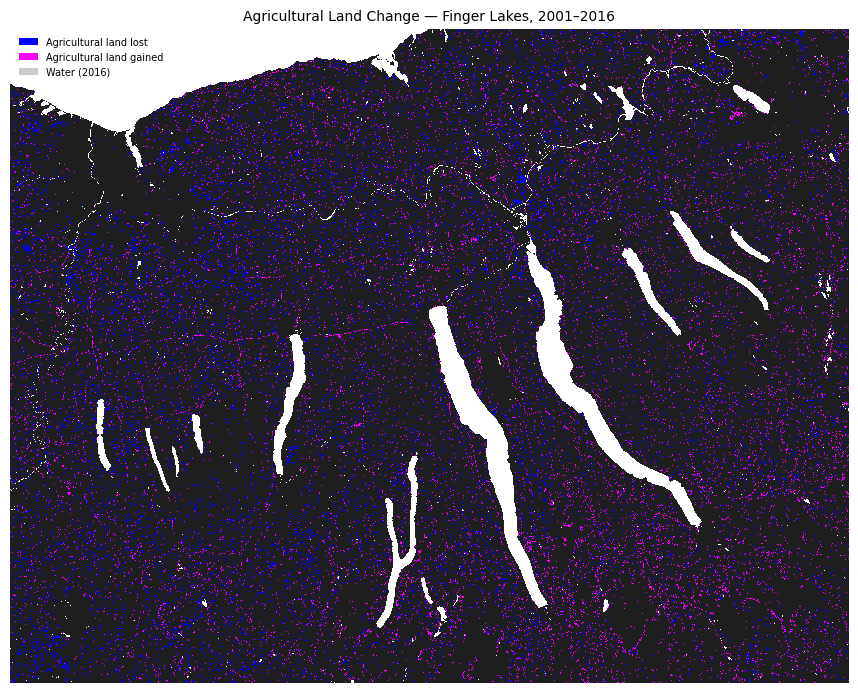

In [17]:
# read the 2016 land cover using the same aligned study window
with rasterio.open(raster_2016_path) as source:
    study_land_cover = source.read(
        1,
        window=study_window,
        masked=True
    )

# identify water pixels using land-cover code 11
# preserve the original missing-data mask
background = np.ma.array(
    (study_land_cover.data == 11).astype("uint8"),
    mask=np.ma.getmaskarray(study_land_cover)
)

# define neutral background colors for land and water
background_cmap = ListedColormap(["#1F1F1F", "#ffffff"])

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw land and water as geographic context
ax.imshow(
    background,
    extent=(left, right, bottom, top),
    origin="upper",
    cmap=background_cmap,
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

# overlay agricultural loss and gain
ax.imshow(
    study_change,
    extent=(left, right, bottom, top),
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

# create legend entries for change and water
legend_items = [
    Patch(facecolor="#0000ff", label="Agricultural land lost"),
    Patch(facecolor="#ff00ff", label="Agricultural land gained"),
    Patch(facecolor="#cccccc", label="Water (2016)")
]

# format the legend and title
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)
ax.set_title(
    "Agricultural Land Change — Finger Lakes, 2001–2016",
    fontsize=10
)
ax.set_axis_off()

plt.show()

In [18]:
# read the full-resolution change values for the study area
with rasterio.open(change_path) as source:
    study_values = source.read(
        1,
        window=study_window,
        masked=True
    )

    # calculate pixel area in square meters
    # this raster uses an equal-area projection with meter units
    pixel_area_m2 = abs(
        source.transform.a * source.transform.e
        - source.transform.b * source.transform.d
    )

# exclude missing pixels from the calculations
valid_values = study_values.compressed()

# count pixels representing agricultural loss and gain
loss_pixels = np.count_nonzero(valid_values == -1)
gain_pixels = np.count_nonzero(valid_values == 1)

# convert square meters to hectares
loss_ha = loss_pixels * pixel_area_m2 / 10_000
gain_ha = gain_pixels * pixel_area_m2 / 10_000
net_change_ha = gain_ha - loss_ha

# display the results for the selected study area
print(f"Agricultural land lost: {loss_ha:,.1f} ha")
print(f"Agricultural land gained: {gain_ha:,.1f} ha")
print(f"Net agricultural change: {net_change_ha:+,.1f} ha")

Agricultural land lost: 78,597.1 ha
Agricultural land gained: 50,314.1 ha
Net agricultural change: -28,282.9 ha


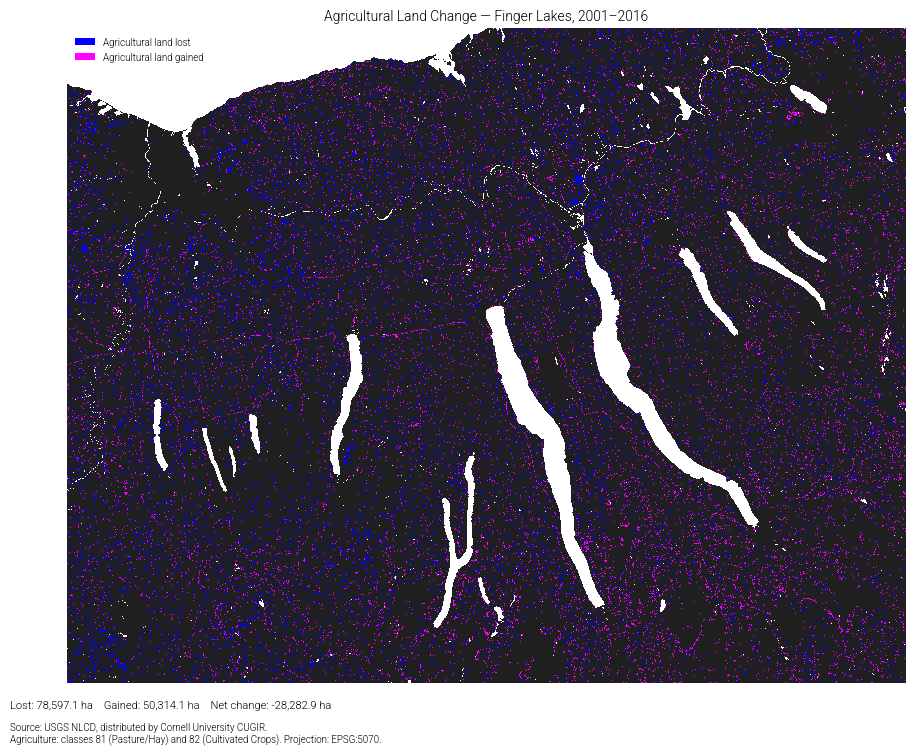

Saved: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/tutorial07_map.pdf


In [20]:
# register the local Roboto font
from matplotlib import font_manager

font_path = Path(
    "Assignement 03 Spatial Relatedness/data/fonts/Roboto-Light.ttf"
)
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = (
    font_manager.FontProperties(fname=str(font_path)).get_name()
)

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw land and water as geographic context
ax.imshow(
    background,
    extent=(left, right, bottom, top),
    origin="upper",
    cmap=background_cmap,
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

# overlay agricultural loss and gain
ax.imshow(
    study_change,
    extent=(left, right, bottom, top),
    origin="upper",
    cmap=change_cmap,
    norm=change_norm,
    interpolation="nearest"
)

# create legend entries for agricultural loss and gain only
legend_items = [
    Patch(facecolor="#0000ff", label="Agricultural land lost"),
    Patch(facecolor="#ff00ff", label="Agricultural land gained")
]

# place the legend below the title on the left
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)

# add the map title and hide coordinate axes
ax.set_title(
    "Agricultural Land Change — Finger Lakes, 2001–2016",
    fontsize=10
)
ax.set_axis_off()

# add area statistics below the map
fig.text(
    0.08,
    0.08,
    f"Lost: {loss_ha:,.1f} ha    "
    f"Gained: {gain_ha:,.1f} ha    "
    f"Net change: {net_change_ha:+,.1f} ha",
    fontsize=8
)

# credit the source and describe the agricultural classification
fig.text(
    0.08,
    0.04,
    "Source: USGS NLCD, distributed by Cornell University CUGIR.\n"
    "Agriculture: classes 81 (Pasture/Hay) and 82 (Cultivated Crops). "
    "Projection: EPSG:5070.",
    fontsize=7
)

# define the PDF destination
pdf_path = Path(
    "/Users/michelle/Desktop/GIT/cdp-mapping-systems/"
    "_fall2026/tutorial07_map.pdf"
)

# save the completed figure before displaying it
with plt.rc_context({"savefig.bbox": None}):
    fig.savefig(pdf_path, format="pdf")

# display the map and confirm the saved location
plt.show()
print("Saved:", pdf_path)